# Introducción

Este notebook tiene dos formas de utilización:

- 1) Queries mediante el nombre de la molécula (en inglés), genera una imagen de nuestro query y además guarda su código SMILES
- 2) Queries por similitud con el código SMILES de la molécula (algunos ejemplos están en el `README.md`, pero puse otros aquí)

El resto de celdas pueden trabajar sin problemas con el modo 1 o modo 2, pero usar el modo 1 o el 2 sobreescribe los datos con cada query.

In [1]:
'''Primeramente, vamos a instalar las dependencias necesarias para realizar
las consultas dentro de la base de datos LOTUS'''
%pip install pandas
%pip install rdkit py3Dmol

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 20.8 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [rdkit]32m1/2 [rdkit]


In [2]:
'''Luego, se importan las bibliotecas Requests, Pandas, RDKit y sus módulos Chem y Draw'''
import pandas as pd
import requests
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.drawOptions.addAtomIndices = False
IPythonConsole.drawOptions.addStereoAnnotation = True


Podemos hacer una búsqueda sencilla empleando el nombre de un producto natural como por ejemplo, el mentol, presente en productos cosméticos como labiales, esencias y el famoso Vaporrub.

> Los nombres de los compuestos deben estar exclusivamente en inglés

Aquí doy unos cuantos que se pueden usar:
- Quercetin
- Cyanidin
- Solanapyrone
- Menthol
- Carvone
- Caffeine
- Delphinidin
- Limonene
- Celastrol
- Catechol
- Cinnamaldehyde

Status code del query: 200
Estructura química del query:


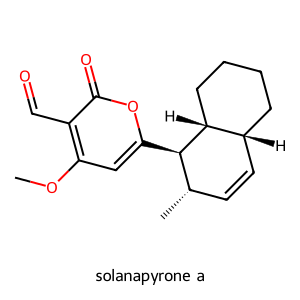

In [22]:
'''Búsqueda por nombre o especie:

Nos van a solicitar el nombre de un producto natural, para posteriormente ejecutar un query simple a la API REST de LOTUS.
Este bloque nos va a devolver el status del query y la estrucutra química del compuesto que estamos buscando'''

compound=input("Introduce el nombre de un producto natural (en inglés):")
url=f"https://lotus.naturalproducts.net/api/search/simple?query={compound}"
response=requests.get(url)
print(f"Status code del query: {response.status_code}")
data=response.json()
df=pd.json_normalize(data,record_path=['naturalProducts'],meta=['originalQuery','determinedInputType'])
smiles=df.at[0,'smiles']
mol=Chem.MolFromSmiles(smiles)
img=Draw.MolToImage(mol,size=(300,300),legend=df['traditional_name'].iloc[0])
print(f"Estructura química del query:")
img


O, podemos emplear una búsqueda por SMILES de la estructura de la molécula
Por ejemplo, podemos buscar:
- Menthol, el compuesto responsable del aroma a menta de *Menta piperita* (menta): C[C@@H]1CC[C@H]([C@@H](C1)O)C(C)C
- Cocaine, un alcaloide de la planta de coca (*Erythroxylum coca*): COC(=O)[C@H]1[C@@H](OC(=O)c2ccccc2)C[C@@H]2CC[C@H]1N2C
- Geraniol, presente en las flores de geranio (*Geranium* sp.): CC(=CCC/C(=C/CO)/C)C
- Delphinidin, una antociandinina que da colores azules a flores como las dalias y las petunias: C1=C(C=C(C(=C1O)[O-])O)C2=C(C=C3C(=CC(=O)C=C3O2)O)O 

In [ ]:
while True:
    smiles=input("Introduce el SMILES de una molécula aquí")
    if not smiles:
        raise Exception("No se introdujo ningún SMILES")
        break
    url=f"https://lotus.naturalproducts.net/api/search/substructure?type=default&max-hits=10&smiles={smiles}"
    response=requests.get(url)
    print(f"Status code del query: {response.status_code}")
    data=response.json()
    print(data) 
    mol=Chem.MolFromSmiles(smiles)
    img=Draw.MolToImage(mol,size=(300,300))
    print(f"Estructura química del query \"{smiles}\"")
    img



In [64]:
''' Este es el armado de nuestro query en 3D, esta celda acepta tanto el output de un query por nombre como
del query por código SMILES'''

from rdkit.Chem import AllChem, rdCoordGen
from rdkit.Chem.Draw import IPythonConsole 
IPythonConsole.ipython_useSVG=True
import py3Dmol

'''Armado, inserción de átomos de hidrógeno y optimización con MMFF94
La función recibe un objeto mol de RDKit, para posteriormente generar
coordenadas XYZ para cada átomo que constituye la molécula'''

def mol3d(mol):
    mol=Chem.MolFromSmiles(smiles)
    rdCoordGen.AddCoords(mol)
    mol=Chem.AddHs(mol,addCoords=True)
    AllChem.EmbedMolecule(mol)
    AllChem.MMFFOptimizeMolecule(mol)
    return mol
mol=mol3d(mol=smiles)

view = py3Dmol.view(
    data=Chem.MolToMolBlock(mol),  # Convert the RDKit molecule for py3Dmol
    style={"stick": {}, "sphere": {"scale": 0.3}}
)
view.zoomTo()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [167]:
'''
Organizamos los datos en un dataframe de Pandas

LOTUS como base de datos tiene un tamaño de 276,521 productos naturales registrados,
creciendo conforme los científicos van reportando estructuras novedosas.

Nota: En química, es usual encontrar compuestos con el mismo peso molecular pero 
con estructura diferente. Inicialmente, añadí un drop_duplicates para eliminar entradas
con el mismo peso molecular, pero vi que habían demasiados isómeros en algunos queries.

'''
df=pd.json_normalize(data['naturalProducts'])
print("¿Cuántas filas y columnas tiene el archivo antes de la limpieza?","\n",df.shape[0],"filas y", df.shape[1],"columnas\n")

# Limpieza de los datos
df=df.dropna(axis=1,how='all')
df.drop(list(df.filter(regex="fragment*")),axis=1,inplace=True)
#df=df.filter(['id','lotus_id','traditional_name','iupac_name','molecular_weight','total_atom_number','contains_sugar','smiles',])

# Resumen final
print("¿Cuántas filas y columnas tiene el archivo tras de la limpieza?","\n",df.shape[0],"filas y", df.shape[1],"columnas\n")
print("Esta es la tabla tras la limpieza:")
display(df.sort_index(axis=0))

¿Cuántas filas y columnas tiene el archivo antes de la limpieza? 
 2 filas y 372 columnas

¿Cuántas filas y columnas tiene el archivo tras de la limpieza? 
 2 filas y 313 columnas

Esta es la tabla tras la limpieza:


,id,lotus_id,wikidata_id,contains_sugar,heavy_atom_number,smiles,inchi,inchikey,inchi2D,inchikey2D,...,taxonomyReferenceObjects.10$x$x$1021/NP980359P.Open Tree of Life,taxonomyReferenceObjects.10$x$x$1021/NP980359P.NCBI,taxonomyReferenceObjects.10$x$x$1021/NP980359P.GBIF Backbone Taxonomy,taxonomyReferenceObjects.10$x$x$1021/NP50020A006.Open Tree of Life,taxonomyReferenceObjects.10$x$x$1021/NP50020A006.GBIF Backbone Taxonomy,taxonomyReferenceObjects.10$x$x$1007/S12272-013-0054-1.ITIS,taxonomyReferenceObjects.10$x$x$1007/S12272-013-0054-1.VASCAN,taxonomyReferenceObjects.10$x$x$1007/S12272-013-0054-1.Open Tree of Life,taxonomyReferenceObjects.10$x$x$1007/S12272-013-0054-1.NCBI,taxonomyReferenceObjects.10$x$x$1007/S12272-013-0054-1.GBIF Backbone Taxonomy
0,604b883712e499616275753f,LTS0029200,http://www.wikidata.org/entity/Q5057534,0,33,CC1=C(O)C(=O)C=C2C1=CC=C1[C@@]3(C)CC[C@@]4(C)C...,"InChI=1S/C29H38O4/c1-17-18-7-8-21-27(4,19(18)1...",KQJSQWZMSAGSHN-JJWQIEBTSA-N,"InChI=1S/C29H38O4/c1-17-18-7-8-21-27(4,19(18)1...",KQJSQWZMSAGSHN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,604b73f612e49961627241b6,LTS0276086,http://www.wikidata.org/entity/Q27108073,0,34,COC(=O)[C@]1(C)CC[C@]2(C)CC[C@]3(C)C4=CC=C5C(=...,"InChI=1S/C30H40O4/c1-18-19-8-9-22-28(4,20(19)1...",JFACETXYABVHFD-WXPPGMDDSA-N,"InChI=1S/C30H40O4/c1-18-19-8-9-22-28(4,20(19)1...",JFACETXYABVHFD,...,"[{'cleaned_organism_id': '6092926', 'organism_...","[{'cleaned_organism_id': '1825831', 'organism_...","[{'cleaned_organism_id': '9747813', 'organism_...","[{'cleaned_organism_id': '6092887', 'organism_...","[{'cleaned_organism_id': '3793206', 'organism_...","[{'cleaned_organism_id': '27937', 'organism_va...","[{'cleaned_organism_id': '107', 'organism_valu...","[{'cleaned_organism_id': '601168', 'organism_v...","[{'cleaned_organism_id': '4305', 'organism_val...","[{'cleaned_organism_id': '6715', 'organism_val..."


In [192]:
'''
LOTUS también tiene datos referentes a la clasificación biológica de los compuestos, pero cuando 
se añadían al DataFrame original, aparecían como 'taxonomyReferenceObjects$x$x$'....' anidados dentro del
data frame principal y encontré que tenía que iterar adentro de ese diccionario y convertirlo con
numpy porque pandas no tiene una herramienta para tablas anidadas como json_normalize, y la API REST
no tiene una opción que solo responda con la taxonomía.

En esta celda, lo que se hace es crear una tabla solo de la taxonomía del compuesto a partir del
data frame original para encontrar las especies y la familia a la que pertenecen según el 'lotus_id' 
de los resultados de nuestro query, para luego hacer un join y así ir quitando duplicados y generar 
una nueva tabla resultado.
'''

rows = []
for np_ in data['naturalProducts']:
    for ref, dbs in np_['taxonomyReferenceObjects'].items():
        for db, organisms in dbs.items():
            for org in organisms:
                rows.append({'lotus_id': np_['lotus_id'],
                             'reference': ref.replace('$x$x$', '.'),
                             'taxonomy_db': db,
                             **org})

taxonomy = pd.DataFrame(rows)
result=pd.merge(df,taxonomy,on='lotus_id',how='right',sort=True)
result=result.drop_duplicates('species')
result=result.dropna(how='all') # Si pongo any, me borra todo
print(f'Nuestro query \"{df['traditional_name'].at[0]}\" se encuentra en la siguiente tabla de especies y familias vegetales')
print(f"Siendo más frecuente en las familia(s) {result['family'].mode().iloc[0]} ({result.groupby('family').count().max().iloc[0]} coincidencias)")
print(f"En el género {result['genus'].mode().iloc[0]} ({result.groupby('genus').count().max().iloc[0]} coincidencias)")
display(result.filter(items=['traditional_name','lotus_id','family','genus','species','taxonomy_db']).sort_values(by=['genus','species']))


Nuestro query "solanapyrone a" se encuentra en la siguiente tabla de especies y familias vegetales
Siendo más frecuente en las familia(s) Didymellaceae (2 coincidencias)
En el género Alternaria (2 coincidencias)


,traditional_name,lotus_id,family,genus,species,taxonomy_db
8,solanapyrone c,LTS0002179,Pleosporaceae,Alternaria,Alternaria solani,Open Tree of Life
36,solanapyrone a,LTS0071736,Pleosporaceae,Alternaria,Alternaria tenuissima,ITIS
12,solanapyrone a,LTS0071736,Apidae,Apis,Apis cerana,iNaturalist
1,solanapyrone c,LTS0002179,Didymellaceae,Ascochyta,Ascochyta rabiei,NCBI
0,solanapyrone c,LTS0002179,Mycosphaerellaceae,Mycosphaerella,Mycosphaerella rabiei,Open Tree of Life
29,solanapyrone a,LTS0071736,Trichosphaeriaceae,Nigrospora,None,Open Tree of Life
3,solanapyrone c,LTS0002179,Didymellaceae,None,Didymella rabiei,Index Fungorum


In [193]:
# Obtener los productos naturales de la respuesta JSON
productos = data.get('naturalProducts', [])

# Construyes los registros de una única tabla
rows = []

for producto in productos:

    # Separamos la información general de la información taxonómica
    producto_base = producto.copy()
    taxonomia = producto_base.pop('taxonomyReferenceObjects', {})

    # Aplanamos los datos generales del producto
    datos_producto = pd.json_normalize(producto_base, sep='_').iloc[0].to_dict()

    # Recorremos los diccionarios de taxonomía
    for referencia, bases_datos in taxonomia.items():
		# Usamos 2 for para que recorra los elementos anidados de tu API
        for base_datos, organismos in bases_datos.items():

            for organismo in organismos:
                # Aplanamos los datos del organismo
                datos_organismo = pd.json_normalize(
                    organismo, sep='_'
                ).iloc[0].to_dict()

                # Unimos los datos en un mismo registro
                registro = {
                    **datos_producto,
                    **datos_organismo,
                    'reference': referencia.replace('$x$x$', '.'),
                    'taxonomy_db': base_datos
                }
                rows.append(registro)
    # Si el producto no tiene información taxonómica,
    # conservamos también su información general
    if not taxonomia:
        rows.append(datos_producto)

# Creamos una sola tabla
df2 = pd.DataFrame(rows)

# Eliminamos columnas completamente vacías
df2 = df.dropna(axis=1, how='any')

print("Dimensiones de nuestra tabla:", df.shape)
display(df2.head())

Dimensiones de nuestra tabla: (6, 203)


,id,lotus_id,wikidata_id,contains_sugar,heavy_atom_number,smiles,inchi,inchikey,inchi2D,inchikey2D,...,ertlFunctionalFragments.[C]=[C],ertlFunctionalFragments.*o*,ertlFunctionalFragments.[c]=O,ertlFunctionalFragmentsPseudoSmiles.[C]=[C],ertlFunctionalFragmentsPseudoSmiles.RO*R,ertlFunctionalFragmentsPseudoSmiles.[C*]=O,pfCounts.count,pfCounts.bits,originalQuery,determinedInputType
0,604b8aa012e499616275d522,LTS0071736,http://www.wikidata.org/entity/Q27117415,0,22,COc1cc([C@@H]2[C@@H](C)C=C[C@H]3CCCC[C@H]32)oc...,InChI=1S/C18H22O4/c1-11-7-8-12-5-3-4-6-13(12)1...,AWQLNKJBXASXDU-SFDCBXKLSA-N,InChI=1S/C18H22O4/c1-11-7-8-12-5-3-4-6-13(12)1...,AWQLNKJBXASXDU,...,1,1,1,1,1,1,130,"[9, 10, 11, 12, 18, 19, 20, 178, 179, 181, 182...",solanapyrone,name
1,604b84eb12e499616274f202,LTS0151140,http://www.wikidata.org/entity/Q27117420,0,22,COc1cc([C@@H]2[C@H](C)C=C[C@@H]3CCCC[C@H]32)oc...,InChI=1S/C18H22O4/c1-11-7-8-12-5-3-4-6-13(12)1...,AWQLNKJBXASXDU-IPJQOSJUSA-N,InChI=1S/C18H22O4/c1-11-7-8-12-5-3-4-6-13(12)1...,AWQLNKJBXASXDU,...,1,1,1,1,1,1,130,"[9, 10, 11, 12, 18, 19, 20, 178, 179, 181, 182...",solanapyrone,name
2,604b830312e499616274a5bf,LTS0157896,http://www.wikidata.org/entity/Q27117422,0,22,COc1cc([C@@H]2[C@H](C)C=C[C@@H]3CCCC[C@H]32)oc...,InChI=1S/C18H24O4/c1-11-7-8-12-5-3-4-6-13(12)1...,YJHFAFJKTXEFDR-IPJQOSJUSA-N,InChI=1S/C18H24O4/c1-11-7-8-12-5-3-4-6-13(12)1...,YJHFAFJKTXEFDR,...,1,1,1,1,1,1,135,"[9, 10, 11, 12, 18, 19, 20, 178, 179, 181, 182...",solanapyrone,name
3,604b827c12e49961627490a3,LTS0215681,http://www.wikidata.org/entity/Q105258380,0,25,C[C@H]1C=C[C@H]2CCCC[C@H]2[C@@H]1c1cc(ONCCO)c(...,InChI=1S/C19H25NO5/c1-12-6-7-13-4-2-3-5-14(13)...,SQOWTAVQIRFHOL-HNSFDTNUSA-N,InChI=1S/C19H25NO5/c1-12-6-7-13-4-2-3-5-14(13)...,SQOWTAVQIRFHOL,...,1,1,1,1,1,1,146,"[9, 10, 11, 12, 14, 18, 19, 20, 178, 179, 181,...",solanapyrone,name
4,604b770912e499616272aaf4,LTS0002179,http://www.wikidata.org/entity/Q27117419,0,24,C[C@H]1C=C[C@H]2CCCC[C@H]2[C@@H]1c1cc(NCCO)c(C...,InChI=1S/C19H25NO4/c1-12-6-7-13-4-2-3-5-14(13)...,FDLXGUBSZCJEGE-HNSFDTNUSA-N,InChI=1S/C19H25NO4/c1-12-6-7-13-4-2-3-5-14(13)...,FDLXGUBSZCJEGE,...,1,1,1,1,1,1,168,"[9, 10, 11, 12, 14, 18, 19, 20, 178, 179, 181,...",solanapyrone,name


Algunos productos naturales existen como **agliconas** y **gliconas**, siendo una aglicona la forma sin azúcar y la glicona la forma unida a uno o más azúcares. 

Ejemplos de productos naturales de esta naturaleza son:

- **Antocianinas y antocianidinas**: Las antocinaninas son compuestos responsables de colores rojizos, morados, rosas y azulados en flores, frutos y hojas de algunas especies de plantas. Estos compuestos son sensibles a la acidez del suelo y, en flores como las dahlias y las petuñas, el color de la flor es indicativo del pH aproximado del suelo. Por otro lado, las antocianinas son la forma de glicona de las antocianidinas, estas últimas siendo la forma sin azúcares de las antocianinas. Ejemplos son la delfinidina (aglicona) y la delfinidina 3-glucósido (glicona).

- **Glicósidos cardiotónicos**: Los glicósidos cardiotónicos son compuestos derivados de una aglicona de esterol vegetal unida a azúcares, tienen un intensivo uso en la medicina como tratamiento para afecciones cardíacas. Ejemplos de glicósidos cardiotónicos son la digoxina (*digoxin*) y la digitoxina (*digitoxin*), de la planta *Digitalis purpurea* o digital.

En la siguiente celda, haremos un agrupamiento según la si hay o no azúcares unidos a las estructuras dentro de nuestro data frame. Esta celda arrojará 0 si la columna `'contains_sugar'` está vacía.

> Nota:
> LOTUS no asigna siempre correctamente si un compuesto contiene azúcares. En algunos queries sí lo detecta.

In [194]:
#display(df.groupby('contains_sugar').count()['lotus_id'])
print(f"En la tabla, tenemos {df[df['contains_sugar'] != 0]['id'].count()} producto(s) natural(es) en su forma de glicona\ny {df[df['contains_sugar'] == 0]['id'].count()} producto(s) natural(es) en su forma algicona ")

En la tabla, tenemos 0 producto(s) natural(es) en su forma de glicona
y 6 producto(s) natural(es) en su forma algicona 


Estructuras moleculares similares a nuestro query "COc1cc([C@@H]2[C@@H](C)C=C[C@H]3CCCC[C@H]32)oc(=O)c1C=O"
0    solanapyrone a
1    solanapyrone d
2    solanapyrone e
3    solanapyrone c
4    solanapyrone c
5    solanapyrone b
Name: traditional_name, dtype: object


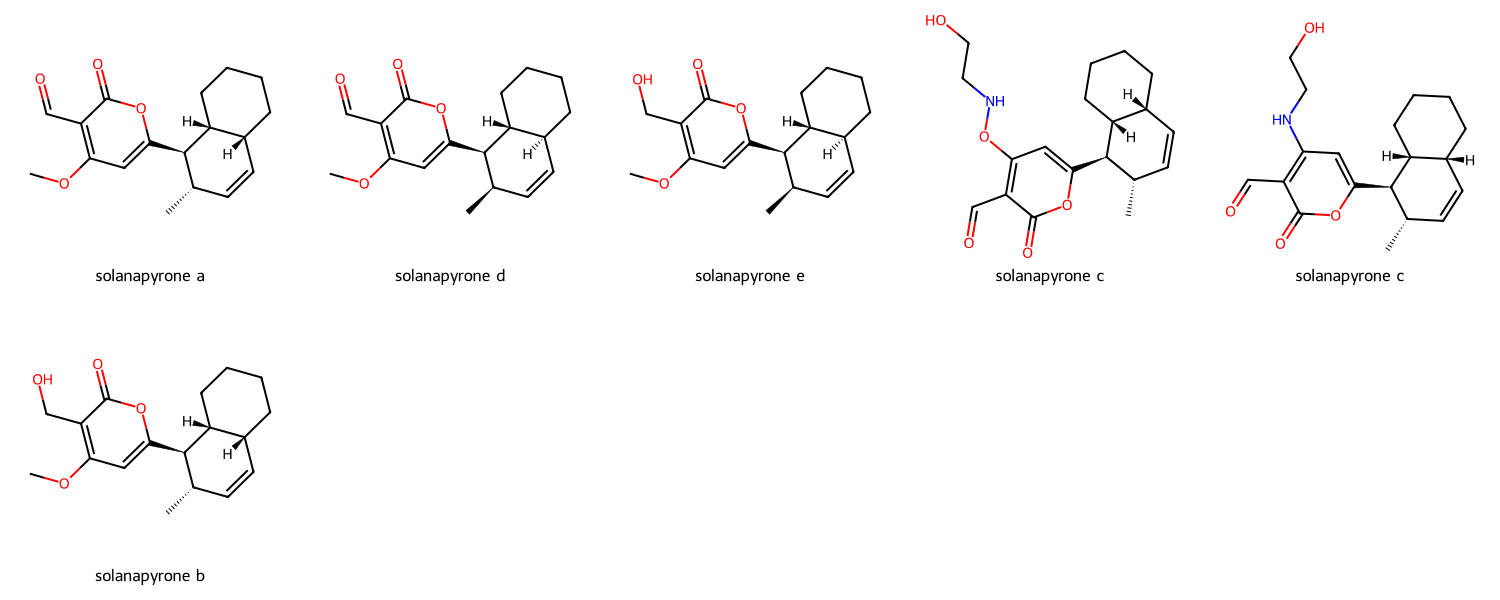

In [195]:
'''
La ventaja de una base de datos como LOTUS es que permite encontrar compuestos con estructuras similares
al de nuestro interés.
Esta celda lo que hace es rescatar todos los códigos SMILES dentro de nuestro data frame y los acomoda en una
imagen compuesta por todos los resultados similares al query (maxhits=int)
'''
mol =  [ Chem.MolFromSmiles(x) for x in df['smiles']]
names=list(df['traditional_name'])
img=Draw.MolsToGridImage(mol,molsPerRow=5,legends=names,subImgSize=(300,300))  
print(f"Estructuras moleculares similares a nuestro query \"{smiles}\"")
print(df['traditional_name'])
img